In [426]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [427]:
df = pd.read_csv("../data/HR_comma_sep.csv")

In [428]:
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [429]:
df.tail()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low
14998,0.37,0.52,2,158,3,0,1,0,support,low


In [430]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 14999
Columns : 10


In [431]:
df.columns

Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'sales', 'salary'],
      dtype='str')

In [432]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  str    
 9   salary                 14999 non-null  str    
dtypes: float64(2), int64(6), str(2)
memory usage: 1.1 MB


In [433]:
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [434]:
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

In [435]:
df.duplicated().sum()

np.int64(3008)

In [436]:
df["left"].value_counts()
df["left"].value_counts(normalize=True) * 100

left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

In [437]:
df = df.drop_duplicates()
df.describe()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000
mean,0.629658,0.716683,3.802852,200.473522,3.364857,0.154282,0.166041,0.016929
std,0.241070,0.168343,1.163238,48.727813,1.330240,0.361234,0.372133,0.129012
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.480000,0.570000,3.000000,157.000000,3.000000,0.000000,0.000000,0.000000
50%,0.660000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.860000,5.000000,243.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [438]:
df.isnull().sum()

satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
sales                    0
salary                   0
dtype: int64

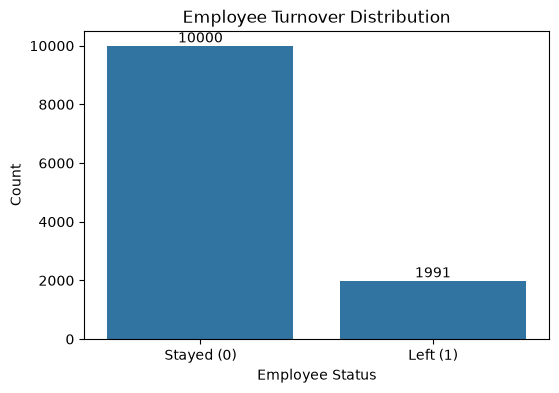

In [439]:
plt.figure(figsize=(6,4))

ax = sns.countplot(data=df, x="left")

plt.title("Employee Turnover Distribution")
plt.xlabel("Employee Status")
plt.ylabel("Count")

ax.set_xticklabels(["Stayed (0)", "Left (1)"])

for container in ax.containers:
    ax.bar_label(container) #type:ignore

plt.show()

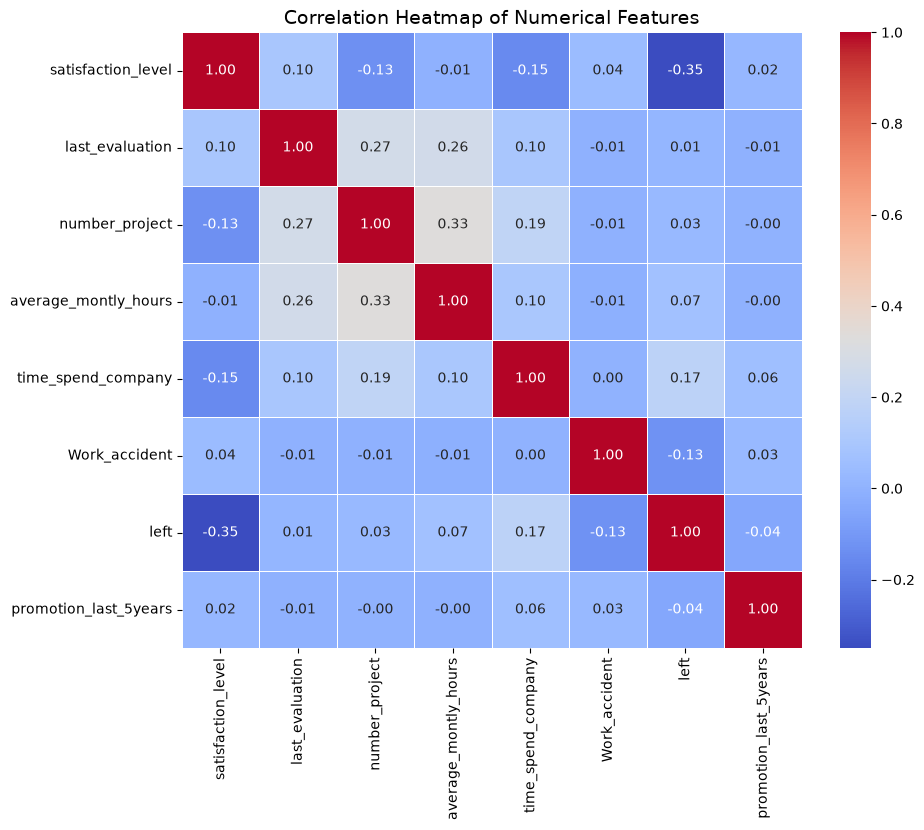

In [440]:
plt.figure(figsize=(10, 8))

correlation = df.select_dtypes(include=["number"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=14)

plt.show()

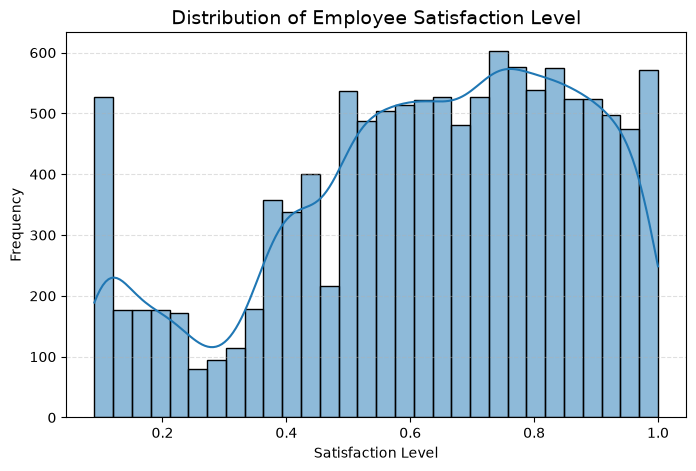

In [441]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="satisfaction_level",
    bins=30,
    kde=True
)

plt.title("Distribution of Employee Satisfaction Level", fontsize=14)
plt.xlabel("Satisfaction Level")
plt.ylabel("Frequency")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

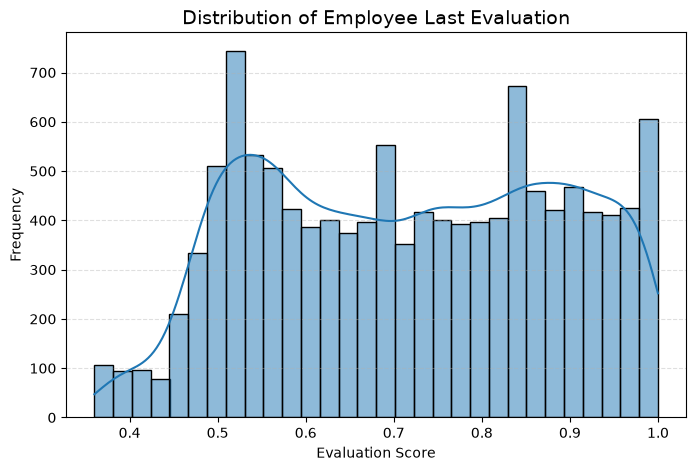

In [442]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="last_evaluation",
    bins=30,
    kde=True
)

plt.title("Distribution of Employee Last Evaluation", fontsize=14)
plt.xlabel("Evaluation Score")
plt.ylabel("Frequency")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

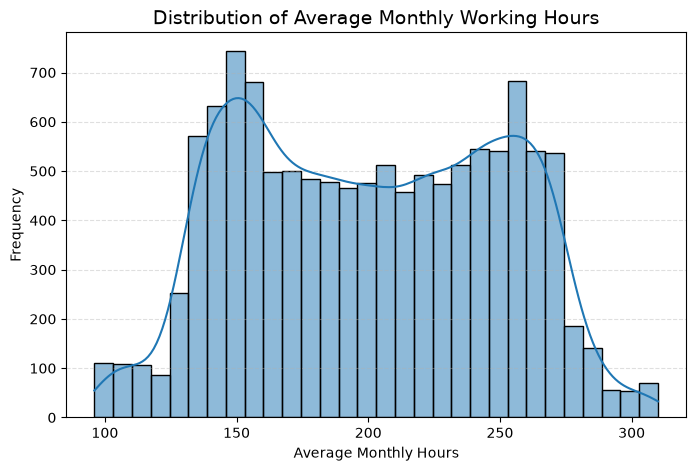

In [443]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="average_montly_hours",
    bins=30,
    kde=True
)

plt.title("Distribution of Average Monthly Working Hours", fontsize=14)
plt.xlabel("Average Monthly Hours")
plt.ylabel("Frequency")

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

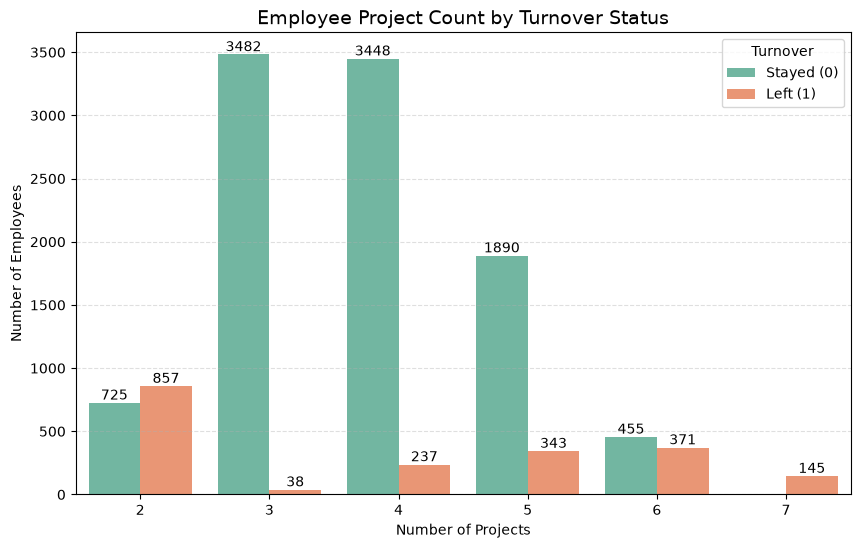

In [444]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x="number_project",
    hue="left",
    palette="Set2"
)

plt.title("Employee Project Count by Turnover Status", fontsize=14)
plt.xlabel("Number of Projects")
plt.ylabel("Number of Employees")

plt.legend(title="Turnover", labels=["Stayed (0)", "Left (1)"])

for container in ax.containers:
    ax.bar_label(container) #type:ignore

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

In [445]:
from sklearn.cluster import KMeans

In [446]:
left_employees = df[df["left"] == 1]

left_employees.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [447]:
X = left_employees[["satisfaction_level", "last_evaluation"]]

X.head()

,satisfaction_level,last_evaluation
0,0.38,0.53
1,0.80,0.86
2,0.11,0.88
3,0.72,0.87
4,0.37,0.52


In [448]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

left_employees["Cluster"] = kmeans.fit_predict(X)

In [449]:
left_employees["Cluster"].value_counts()

Cluster
0    902
1    555
2    534
Name: count, dtype: int64

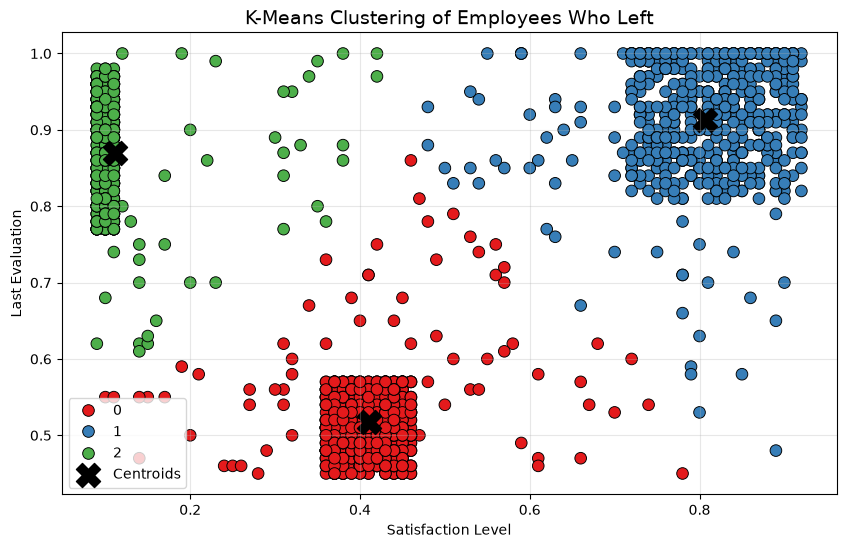

In [450]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=left_employees,
    x="satisfaction_level",
    y="last_evaluation",
    hue="Cluster",
    palette="Set1",
    s=70,
    edgecolor="black"
)

# Plot cluster centers
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=300,
    marker="X",
    c="black",
    label="Centroids"
)

plt.title("K-Means Clustering of Employees Who Left", fontsize=14)
plt.xlabel("Satisfaction Level")
plt.ylabel("Last Evaluation")

plt.grid(alpha=0.3)
plt.legend()

plt.show()

In [451]:
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=[
        "satisfaction_level",
        "last_evaluation"
    ]
)

centers.index = [
    "Cluster 0",
    "Cluster 1",
    "Cluster 2"
]

centers

,satisfaction_level,last_evaluation
Cluster 0,0.410133,0.517195
Cluster 1,0.805874,0.912577
Cluster 2,0.111199,0.869064


In [452]:
X = df.drop("left", axis=1)
y = df["left"]

print("Feature Shape :", X.shape)
print("Target Shape  :", y.shape)

Feature Shape : (11991, 9)
Target Shape  : (11991,)


In [453]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

Categorical Columns:
Index(['sales', 'salary'], dtype='str')

Numerical Columns:
Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident',
       'promotion_last_5years'],
      dtype='str')


In [454]:
X = pd.get_dummies(
    X,
    columns=categorical_cols, #type: ignore
    drop_first=True,
    dtype=int
)

print("New Shape :", X.shape)
X.head()

New Shape : (11991, 18)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,1,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,1,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,1,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,1,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,1,0,0,1,0


In [455]:
X.info()

<class 'pandas.DataFrame'>
Index: 11991 entries, 0 to 11999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     11991 non-null  float64
 1   last_evaluation        11991 non-null  float64
 2   number_project         11991 non-null  int64  
 3   average_montly_hours   11991 non-null  int64  
 4   time_spend_company     11991 non-null  int64  
 5   Work_accident          11991 non-null  int64  
 6   promotion_last_5years  11991 non-null  int64  
 7   sales_RandD            11991 non-null  int64  
 8   sales_accounting       11991 non-null  int64  
 9   sales_hr               11991 non-null  int64  
 10  sales_management       11991 non-null  int64  
 11  sales_marketing        11991 non-null  int64  
 12  sales_product_mng      11991 non-null  int64  
 13  sales_sales            11991 non-null  int64  
 14  sales_support          11991 non-null  int64  
 15  sales_technical   

In [456]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=123,
    stratify=y
)

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (9592, 18)
Testing Features  : (2399, 18)
Training Labels   : (9592,)
Testing Labels    : (2399,)


In [457]:
print("Before SMOTE")
print(y_train.value_counts())

Before SMOTE
left
0    7999
1    1593
Name: count, dtype: int64


In [458]:
from imblearn.over_sampling import SMOTE


In [459]:
smote = SMOTE(random_state=123)

X_train_smote, y_train_smote = smote.fit_resample( #type: ignore
    X_train,
    y_train
)

print("Class distribution BEFORE SMOTE:")
print(y_train.value_counts())

print("\nClass distribution AFTER SMOTE:")
print(y_train_smote.value_counts())

Class distribution BEFORE SMOTE:
left
0    7999
1    1593
Name: count, dtype: int64

Class distribution AFTER SMOTE:
left
0    7999
1    7999
Name: count, dtype: int64


In [460]:
print("Original Training Features :", X_train.shape)
print("SMOTE Training Features    :", X_train_smote.shape)

print("Original Training Target   :", y_train.shape)
print("SMOTE Training Target      :", y_train_smote.shape)

print("\nTesting Features           :", X_test.shape)
print("Testing Target             :", y_test.shape)

Original Training Features : (9592, 18)
SMOTE Training Features    : (15998, 18)
Original Training Target   : (9592,)
SMOTE Training Target      : (15998,)

Testing Features           : (2399, 18)
Testing Target             : (2399,)


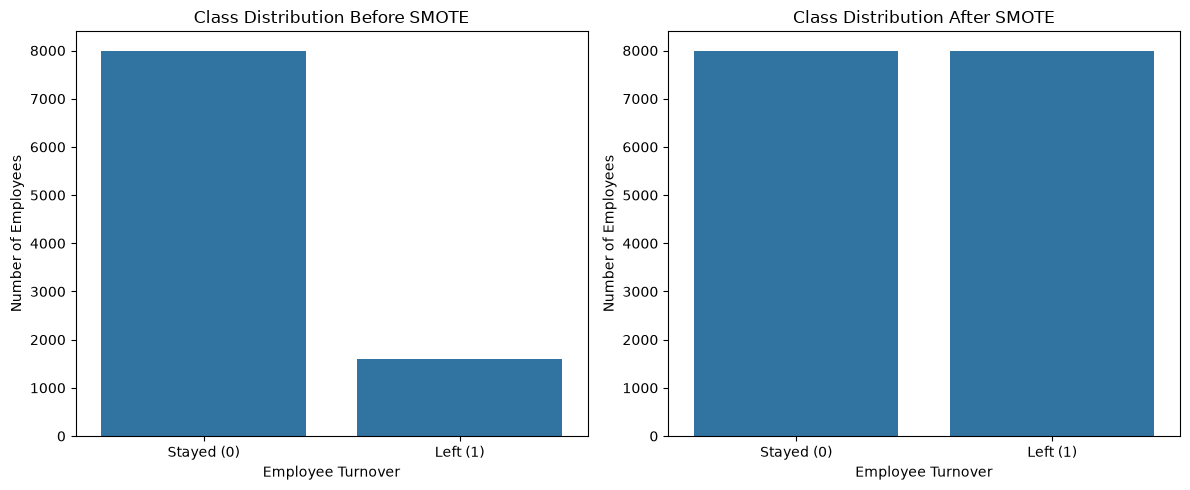

In [461]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title("Class Distribution Before SMOTE")
axes[0].set_xlabel("Employee Turnover")
axes[0].set_ylabel("Number of Employees")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Stayed (0)", "Left (1)"])

# After SMOTE
sns.countplot(
    x=y_train_smote, #type: ignore
    ax=axes[1]
)

axes[1].set_title("Class Distribution After SMOTE")
axes[1].set_xlabel("Employee Turnover")
axes[1].set_ylabel("Number of Employees")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Stayed (0)", "Left (1)"])

plt.tight_layout()
plt.show()

In [462]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import StratifiedKFold, cross_val_score

In [463]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=123
)

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=123,
    n_jobs=-1
)

gradient_boosting_model = GradientBoostingClassifier(
    random_state=123
)

In [464]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

In [465]:
logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train_smote, #type: ignore
    y_train_smote,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Logistic Regression - 5 Fold CV Accuracy")
print(logistic_cv_scores) #type: ignore

print("\nMean Accuracy:", logistic_cv_scores.mean()) #type: ignore
print("Standard Deviation:", logistic_cv_scores.std()) #type: ignore

Logistic Regression - 5 Fold CV Accuracy
[0.8284375  0.8215625  0.8425     0.82525789 0.82744608]

Mean Accuracy: 0.8290407939981244
Standard Deviation: 0.0071315150265041545


In [466]:
rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train_smote, #type: ignore
    y_train_smote,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Random Forest - 5 Fold CV Accuracy")
print(rf_cv_scores)

print("\nMean Accuracy:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest - 5 Fold CV Accuracy
[0.975625   0.976875   0.980625   0.97405439 0.97530478]

Mean Accuracy: 0.9764968349484213
Standard Deviation: 0.0022508384083148175


In [467]:
gb_cv_scores = cross_val_score(
    gradient_boosting_model,
    X_train_smote, #type: ignore
    y_train_smote,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Gradient Boosting - 5 Fold CV Accuracy")
print(gb_cv_scores)

print("\nMean Accuracy:", gb_cv_scores.mean())
print("Standard Deviation:", gb_cv_scores.std())

Gradient Boosting - 5 Fold CV Accuracy
[0.955625   0.956875   0.9596875  0.95498593 0.95404814]

Mean Accuracy: 0.9562443146295717
Standard Deviation: 0.001951591505260021


In [468]:
cv_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "Mean CV Accuracy": [
        logistic_cv_scores.mean(),#type: ignore
        rf_cv_scores.mean(),
        gb_cv_scores.mean()
    ],
    
    "CV Std": [
        logistic_cv_scores.std(), #type: ignore
        rf_cv_scores.std(),
        gb_cv_scores.std()
    ]
})

cv_results = cv_results.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

cv_results

,Model,Mean CV Accuracy,CV Std
0,Random Forest,0.976497,0.002251
1,Gradient Boosting,0.956244,0.001952
2,Logistic Regression,0.829041,0.007132


In [469]:
# Logistic Regression
logistic_model.fit(
    X_train_smote,
    y_train_smote
)

# Random Forest
random_forest_model.fit(
    X_train_smote,
    y_train_smote
)

# Gradient Boosting
gradient_boosting_model.fit(
    X_train_smote,
    y_train_smote
)

print("All three models trained successfully!")

All three models trained successfully!


In [470]:
y_pred_logistic = logistic_model.predict(X_test)

y_pred_rf = random_forest_model.predict(X_test)

y_pred_gb = gradient_boosting_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [471]:
from sklearn.metrics import classification_report

In [472]:
print("=" * 60)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=["Stayed (0)", "Left (1)"]
    )
)

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Stayed (0)       0.91      0.79      0.84      2001
    Left (1)       0.37      0.63      0.46       398

    accuracy                           0.76      2399
   macro avg       0.64      0.71      0.65      2399
weighted avg       0.82      0.76      0.78      2399



In [473]:
print("=" * 60)
print("RANDOM FOREST - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Stayed (0)", "Left (1)"]
    )
)

RANDOM FOREST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Stayed (0)       0.98      0.98      0.98      2001
    Left (1)       0.92      0.91      0.91       398

    accuracy                           0.97      2399
   macro avg       0.95      0.95      0.95      2399
weighted avg       0.97      0.97      0.97      2399



In [474]:
print("=" * 60)
print("GRADIENT BOOSTING - CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=["Stayed (0)", "Left (1)"]
    )
)

GRADIENT BOOSTING - CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Stayed (0)       0.98      0.97      0.98      2001
    Left (1)       0.85      0.92      0.88       398

    accuracy                           0.96      2399
   macro avg       0.92      0.94      0.93      2399
weighted avg       0.96      0.96      0.96      2399



In [475]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [476]:
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [477]:
auc_logistic = roc_auc_score(y_test, y_prob_logistic)

auc_rf = roc_auc_score(y_test, y_prob_rf)

auc_gb = roc_auc_score(y_test, y_prob_gb)

print("ROC-AUC Scores")
print("-" * 30)

print(f"Logistic Regression : {auc_logistic:.4f}")
print(f"Random Forest       : {auc_rf:.4f}")
print(f"Gradient Boosting   : {auc_gb:.4f}")

ROC-AUC Scores
------------------------------
Logistic Regression : 0.7853
Random Forest       : 0.9737
Gradient Boosting   : 0.9771


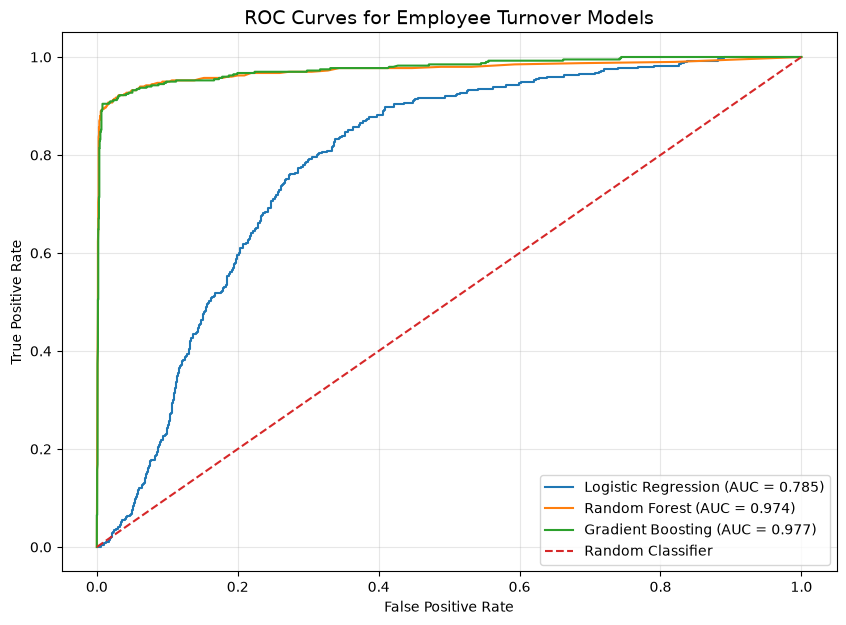

In [478]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

fpr_gb, tpr_gb, _ = roc_curve(
    y_test,
    y_prob_gb
)

plt.figure(figsize=(10, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {auc_logistic:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {auc_gb:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curves for Employee Turnover Models", fontsize=14)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [479]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

print("\nGradient Boosting Confusion Matrix:")
print(cm_gb)

Logistic Regression Confusion Matrix:
[[1571  430]
 [ 149  249]]

Random Forest Confusion Matrix:
[[1969   32]
 [  37  361]]

Gradient Boosting Confusion Matrix:
[[1935   66]
 [  31  367]]


<Figure size 600x500 with 0 Axes>

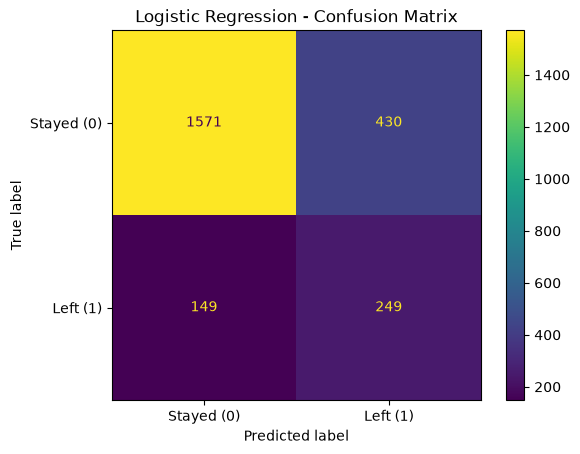

In [480]:
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=["Stayed (0)", "Left (1)"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")

plt.show()

<Figure size 600x500 with 0 Axes>

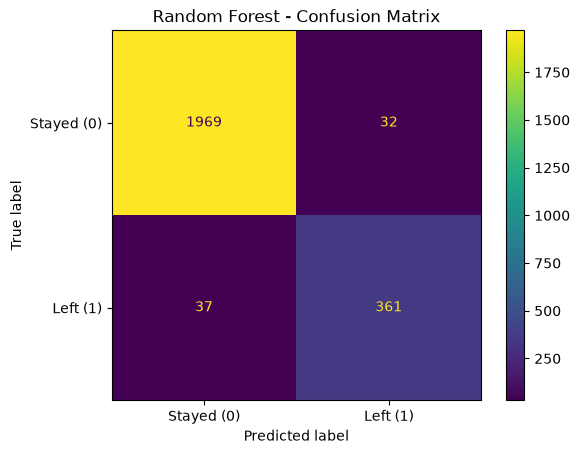

In [481]:
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Stayed (0)", "Left (1)"]
).plot()

plt.title("Random Forest - Confusion Matrix")

plt.show()

<Figure size 600x500 with 0 Axes>

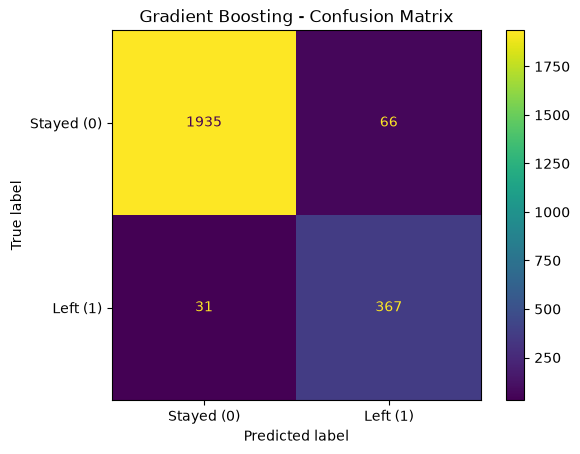

In [482]:
plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=["Stayed (0)", "Left (1)"]
).plot()

plt.title("Gradient Boosting - Confusion Matrix")

plt.show()

In [483]:
turnover_probability = random_forest_model.predict_proba(X_test)[:, 1]

print("First 10 Turnover Probabilities:")
print(turnover_probability[:10])

First 10 Turnover Probabilities:
[0.12  0.26  0.035 0.915 0.005 1.    0.125 0.03  0.01  0.02 ]


In [484]:
test_results = X_test.copy()

test_results["Actual_Left"] = y_test.values

test_results["Turnover_Probability"] = turnover_probability

test_results["Turnover_Score"] = (
    test_results["Turnover_Probability"] * 100
)

test_results.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium,Actual_Left,Turnover_Probability,Turnover_Score
8578,0.82,0.95,6,191,6,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0.120,12.0
5756,0.18,0.86,5,267,4,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0.260,26.0
3994,0.63,0.98,4,160,2,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0.035,3.5
1784,0.43,0.51,2,149,3,1,0,0,1,0,0,0,0,0,0,0,0,1,1,0.915,91.5
10508,0.51,0.98,4,245,3,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0.005,0.5


In [485]:
def classify_risk(probability):

    if probability < 0.20:
        return "Safe Zone"

    elif probability < 0.60:
        return "Low-Risk Zone"

    elif probability < 0.90:
        return "Medium-Risk Zone"

    else:
        return "High-Risk Zone"


test_results["Risk_Zone"] = (
    test_results["Turnover_Probability"]
    .apply(classify_risk)
)

In [486]:
risk_distribution = (
    test_results["Risk_Zone"]
    .value_counts()
)

risk_distribution

Risk_Zone
Safe Zone           1838
High-Risk Zone       332
Low-Risk Zone        185
Medium-Risk Zone      44
Name: count, dtype: int64

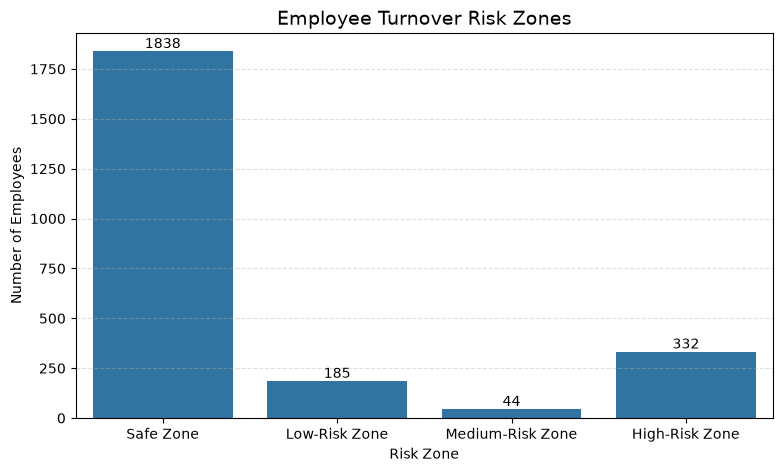

In [487]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=test_results,
    x="Risk_Zone",
    order=[
        "Safe Zone",
        "Low-Risk Zone",
        "Medium-Risk Zone",
        "High-Risk Zone"
    ]
)

plt.title("Employee Turnover Risk Zones", fontsize=14)
plt.xlabel("Risk Zone")
plt.ylabel("Number of Employees")

for container in ax.containers:
    ax.bar_label(container) #type: ignore

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

In [488]:
risk_order = [
    "Safe Zone",
    "Low-Risk Zone",
    "Medium-Risk Zone",
    "High-Risk Zone"
]

risk_summary = (
    test_results["Risk_Zone"]
    .value_counts()
    .reindex(risk_order)
    .reset_index()
)

risk_summary.columns = [
    "Risk Zone",
    "Employee Count"
]

risk_summary["Percentage"] = (
    risk_summary["Employee Count"]
    / len(test_results)
    * 100
)

risk_summary["Percentage"] = (
    risk_summary["Percentage"].round(2)
)

risk_summary

,Risk Zone,Employee Count,Percentage
0,Safe Zone,1838,76.62
1,Low-Risk Zone,185,7.71
2,Medium-Risk Zone,44,1.83
3,High-Risk Zone,332,13.84


In [489]:
risk_performance = (
    test_results
    .groupby("Risk_Zone")["Actual_Left"]
    .agg(
        Employee_Count="count",
        Actual_Left="sum",
        Actual_Turnover_Rate="mean"
    )
    .reindex(risk_order)
)

risk_performance["Actual_Turnover_Rate"] = (
    risk_performance["Actual_Turnover_Rate"] * 100
).round(2)

risk_performance

,Employee_Count,Actual_Left,Actual_Turnover_Rate
Risk_Zone,,,
Safe Zone,1838,21,1.14
Low-Risk Zone,185,21,11.35
Medium-Risk Zone,44,29,65.91
High-Risk Zone,332,327,98.49


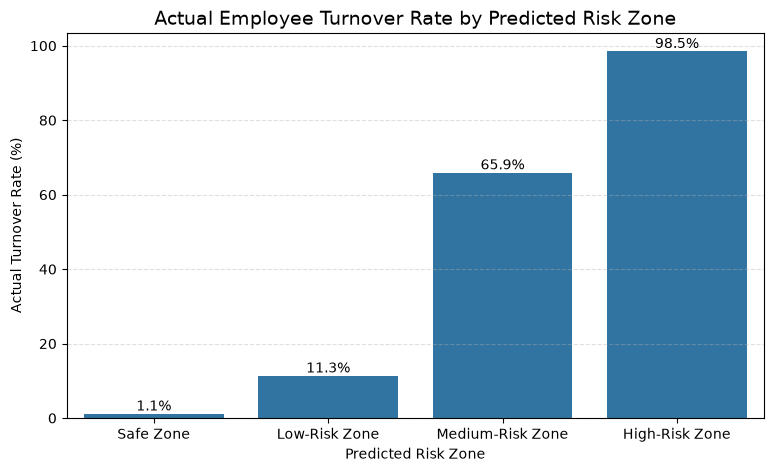

In [490]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=risk_performance.reset_index(),
    x="Risk_Zone",
    y="Actual_Turnover_Rate",
    order=risk_order
)

plt.title("Actual Employee Turnover Rate by Predicted Risk Zone", fontsize=14)
plt.xlabel("Predicted Risk Zone")
plt.ylabel("Actual Turnover Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%") #type: ignore

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.show()

In [ ]:
import os
import joblib

# Create models directory if it doesn't exist
os.makedirs("models", exist_ok=True)

# Save Logistic Regression
joblib.dump(
    logistic_model,
    "../models/logistic_regression.pkl"
)

# Save Random Forest
joblib.dump(
    random_forest_model,
    "../models/random_forest.pkl"
)

# Save Gradient Boosting
joblib.dump(
    gradient_boosting_model,
    "../models/gradient_boosting.pkl"
)

print("All models saved successfully!")

All models saved successfully!


In [492]:
print("Saved model files:")

for file in os.listdir("models"):
    print("-", file)

Saved model files:
- gradient_boosting.pkl
- logistic_regression.pkl
- random_forest.pkl


In [ ]:
loaded_logistic = joblib.load(
    "../models/logistic_regression.pkl"
)

loaded_rf = joblib.load(
    "../models/random_forest.pkl"
)

loaded_gb = joblib.load(
    "../models/gradient_boosting.pkl"
)

print("All models loaded successfully!")

All models loaded successfully!


In [494]:
rf_test_predictions = loaded_rf.predict(X_test)

print("Random Forest predictions:")
print(rf_test_predictions[:10])

Random Forest predictions:
[0 0 0 1 0 1 0 0 0 0]


In [495]:
rf_test_probabilities = loaded_rf.predict_proba(X_test)[:, 1]

print("Random Forest turnover probabilities:")
print(rf_test_probabilities[:10])

Random Forest turnover probabilities:
[0.12  0.26  0.035 0.915 0.005 1.    0.125 0.03  0.01  0.02 ]
